In [1]:
# load in the packages you will need for your analysis

import pandas as pd  # pandas is a package for data analysis and manipulation
import seaborn as sns  # seaborn is a data visualization package
import matplotlib.pyplot as plt # matplotlib is the OG python plotting library and really useful for formatting 

In [2]:
# Load the coastal cleanup data into a dataframe
infile = "International_Coastal_cleanup.csv"
data = pd.read_csv(infile, sep=',',low_memory=False)

The International coastal cleanup data is from the Norfolk Open Data website. This group is an international initiative that takes place from September 1st to October 31st. This event gloablly removes trash from beaches and different water systems. Volunteer groups are used to help pick up all the trash and to clean the environement. This dataset is updated anually and was last updated January 9, 2026 by Keep Norfolk Beautiful.

In [3]:
# print the information about the data in the dataframe
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 53 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Area                                       77 non-null     str    
 1   Date                                       77 non-null     str    
 2   Cigarette Butts                            77 non-null     str    
 3   Food Wrappers (candy, chips, etc.)         77 non-null     str    
 4   Take Out/Away Containers (Plastic)         77 non-null     int64  
 5   Take Out/Away Containers (Foam)            77 non-null     int64  
 6   Bottle Caps (Plastic)                      77 non-null     int64  
 7   Bottle Caps (Metal)                        77 non-null     str    
 8   Lids (Plastic)                             77 non-null     int64  
 9   Straws, Stirrers                           77 non-null     int64  
 10  Forks, Knives, Spoons                  

The dataset contains 77 observations and 53 variables. There are no missing values. Some of the data is a string when it should actually
be a numeric value

In [4]:
# Examine a variable that should be numeric but is stored as a string

data["Cigarette Butts"].head(15)

0        40
1        20
2         7
3       220
4       800
5        50
6       203
7       123
8       655
9     1,271
10    1,119
11       44
12       49
13       56
14       24
Name: Cigarette Butts, dtype: str

In [5]:
# Examine the total items column

data["Total Items Collected"].head(15)

0        85
1     1,073
2       337
3     1,866
4     5,238
5       587
6       680
7       401
8     1,105
9     4,887
10    4,551
11      360
12    1,104
13      988
14      999
Name: Total Items Collected, dtype: str

In [6]:
# Returns a list of column names stored as strings/objects
string_cols = data.select_dtypes(include=['object', 'string']).columns.tolist()
print(string_cols)

['Area', 'Date', 'Cigarette Butts', 'Food Wrappers (candy, chips, etc.)', 'Bottle Caps (Metal)', 'Beverage Bottles (Glass)', 'Personal Hygiene (Clean Swell)', 'Glass Pieces', 'Plastic Pieces', 'Total Items Collected', 'Total Pounds of Litter Collected']


In [7]:
# Clean symbols/commas across multiple columns, then convert to float
cols_with_symbols = ['Cigarette Butts',
    'Food Wrappers (candy, chips, etc.)',
    'Bottle Caps (Metal)',
    'Beverage Bottles (Glass)',
    'Personal Hygiene (Clean Swell)',
    'Glass Pieces',
    'Plastic Pieces',
    'Total Items Collected',
    'Total Pounds of Litter Collected']

for col in cols_with_symbols:
    data[col] = (
        data[col]
        .astype(str)
        .str.replace(r',', '', regex=True)
        .str.strip()
    )
    data[col] = pd.to_numeric(data[col], errors='coerce')

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 53 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Area                                       77 non-null     str    
 1   Date                                       77 non-null     str    
 2   Cigarette Butts                            77 non-null     int64  
 3   Food Wrappers (candy, chips, etc.)         77 non-null     int64  
 4   Take Out/Away Containers (Plastic)         77 non-null     int64  
 5   Take Out/Away Containers (Foam)            77 non-null     int64  
 6   Bottle Caps (Plastic)                      77 non-null     int64  
 7   Bottle Caps (Metal)                        77 non-null     int64  
 8   Lids (Plastic)                             77 non-null     int64  
 9   Straws, Stirrers                           77 non-null     int64  
 10  Forks, Knives, Spoons                  

Several numerical variables were stored as strings because some values contained commas. These columns were cleaned by removing the commas and converting them to numeric values. After the conversion, all variables had 77 observations, so none of the values were last after doing the conversion.

In [9]:
# Shows the count of NaN values in each column
print(data.isna().sum())

Area                                         0
Date                                         0
Cigarette Butts                              0
Food Wrappers (candy, chips, etc.)           0
Take Out/Away Containers (Plastic)           0
Take Out/Away Containers (Foam)              0
Bottle Caps (Plastic)                        0
Bottle Caps (Metal)                          0
Lids (Plastic)                               0
Straws, Stirrers                             0
Forks, Knives, Spoons                        0
Beverage Bottles (Plastic)                   0
Beverage Bottles (Glass)                     0
Beverage Cans                                0
Grocery Bags (Plastic)                       0
Other Plastic Bags                           0
Paper Bags                                   0
Cups, Plates (Paper)                         0
Cups, Plates (Plastic)                       0
Cups, Plates (Foam)                          0
Fishing Buoys, Pots & Traps                  0
Fishing Net &

There are zero null values, so everything is a valid number and is not missing.

In [10]:
# Calculate descriptive statistics for the numerical variables

data.describe()

,Cigarette Butts,"Food Wrappers (candy, chips, etc.)",Take Out/Away Containers (Plastic),Take Out/Away Containers (Foam),Bottle Caps (Plastic),Bottle Caps (Metal),Lids (Plastic),"Straws, Stirrers","Forks, Knives, Spoons",Beverage Bottles (Plastic),...,Tampons/Tampon Applicators,Personal Hygiene (Clean Swell),Foam Pieces,Glass Pieces,Plastic Pieces,Total Items Collected,Total Pounds of Litter Collected,Number of Volunteers,Volunteer Hours,Number of Miles
count,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,...,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.000000,77.00000,77.000000
mean,480.194805,154.220779,18.363636,13.714286,98.337662,245.376623,23.350649,50.558442,13.909091,68.922078,...,0.922078,39.116883,64.441558,119.558442,267.233766,2059.474026,200.558442,18.896104,37.37013,1.530909
std,832.501510,219.833108,21.944253,18.943724,148.793093,924.419064,26.738877,62.141920,20.238825,92.227089,...,2.113654,239.313600,128.515767,359.613370,875.693753,3408.767664,379.650445,27.249135,57.04352,1.486711
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
25%,50.000000,26.000000,3.000000,1.000000,16.000000,1.000000,6.000000,11.000000,1.000000,15.000000,...,0.000000,0.000000,0.000000,0.000000,5.000000,337.000000,30.000000,5.000000,9.00000,1.000000
50%,140.000000,64.000000,8.000000,6.000000,43.000000,15.000000,13.000000,24.000000,7.000000,34.000000,...,0.000000,0.000000,14.000000,12.000000,63.000000,851.000000,80.000000,11.000000,22.00000,1.000000
75%,439.000000,177.000000,31.000000,19.000000,107.000000,39.000000,33.000000,72.000000,20.000000,70.000000,...,1.000000,10.000000,58.000000,77.000000,180.000000,1936.000000,180.000000,22.000000,38.00000,2.000000
max,3639.000000,1203.000000,90.000000,106.000000,780.000000,6269.000000,109.000000,368.000000,136.000000,395.000000,...,14.000000,2093.000000,750.000000,2806.000000,7415.000000,20544.000000,2545.000000,178.000000,396.00000,10.000000


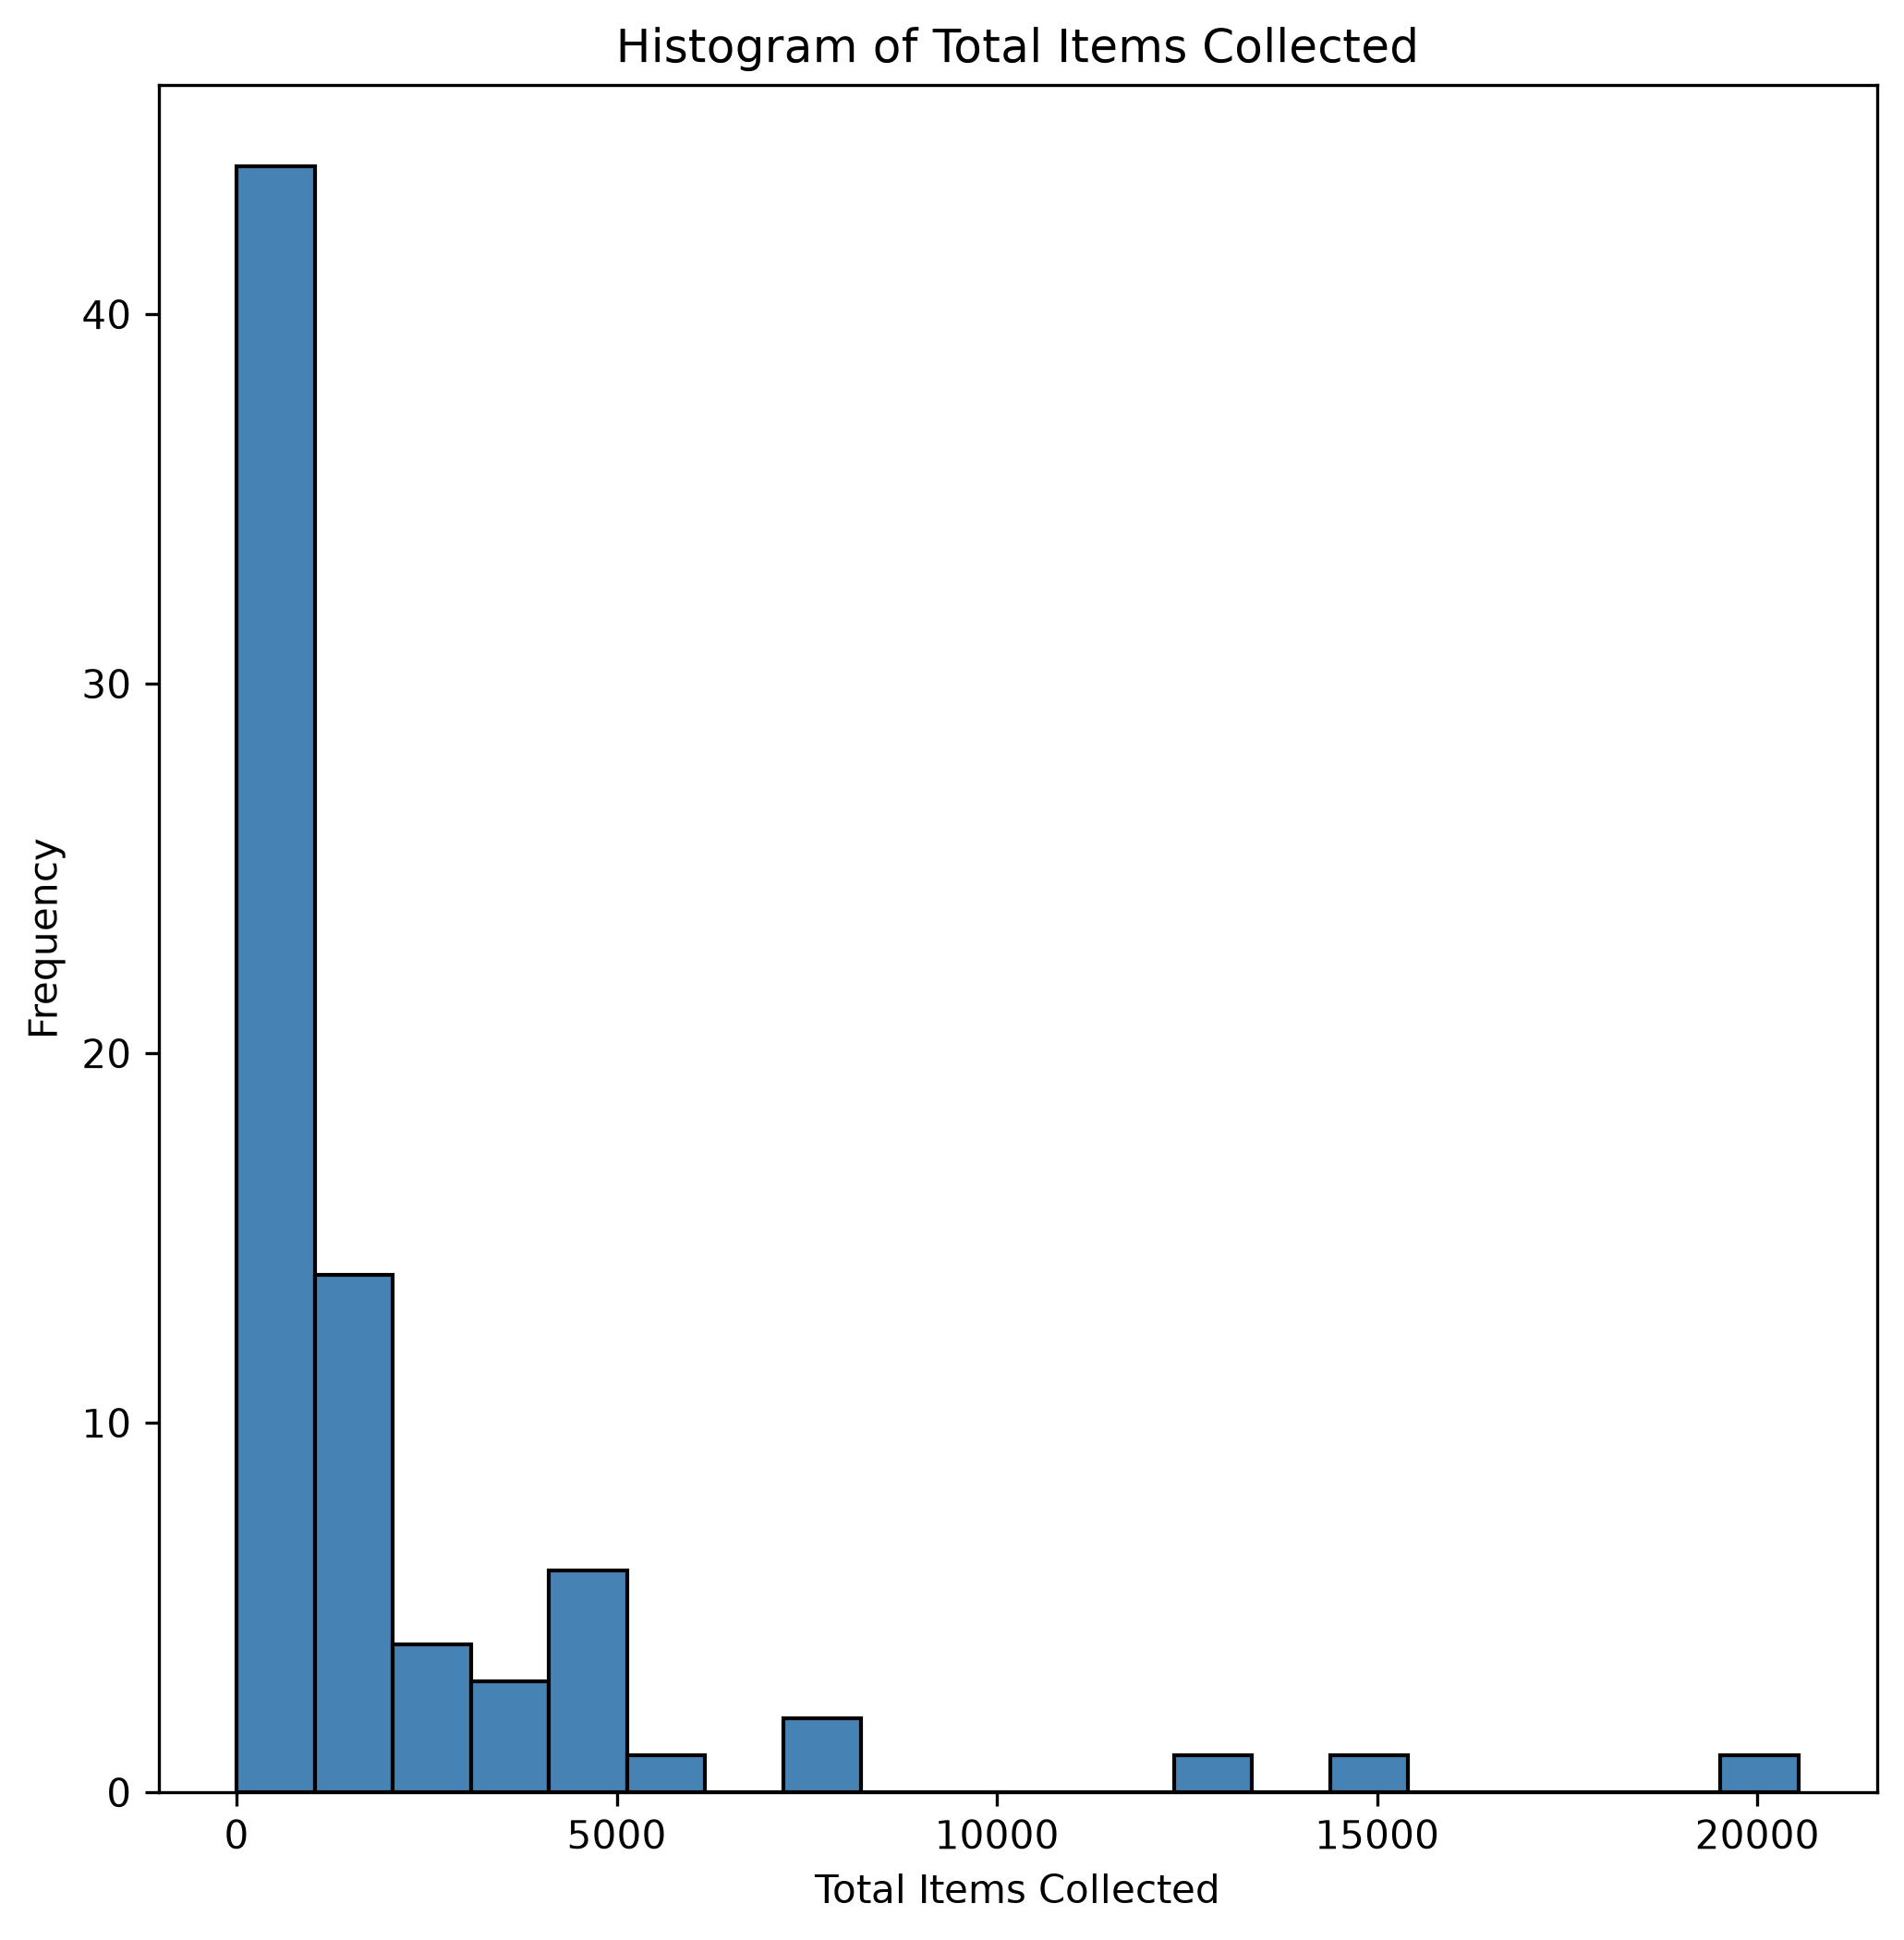

In [11]:
# histograms are the best, fastest data "check" for single variables
# in matplotlib, this is plt.hist

fig, ax = plt.subplots(1, figsize = (8,8), dpi = 300)

plt.hist(data["Total Items Collected"].dropna(), bins=20, 
         color="steelblue", edgecolor="black")

plt.title("Histogram of Total Items Collected")
plt.xlabel("Total Items Collected")
plt.ylabel("Frequency")

plt.show()

The total number of items collected is most concentrated generally below 2000 items, but there are still some collections that were over 5000. Some of the values go as high as approximately 20,000 items. This is a right skewed distribution. 

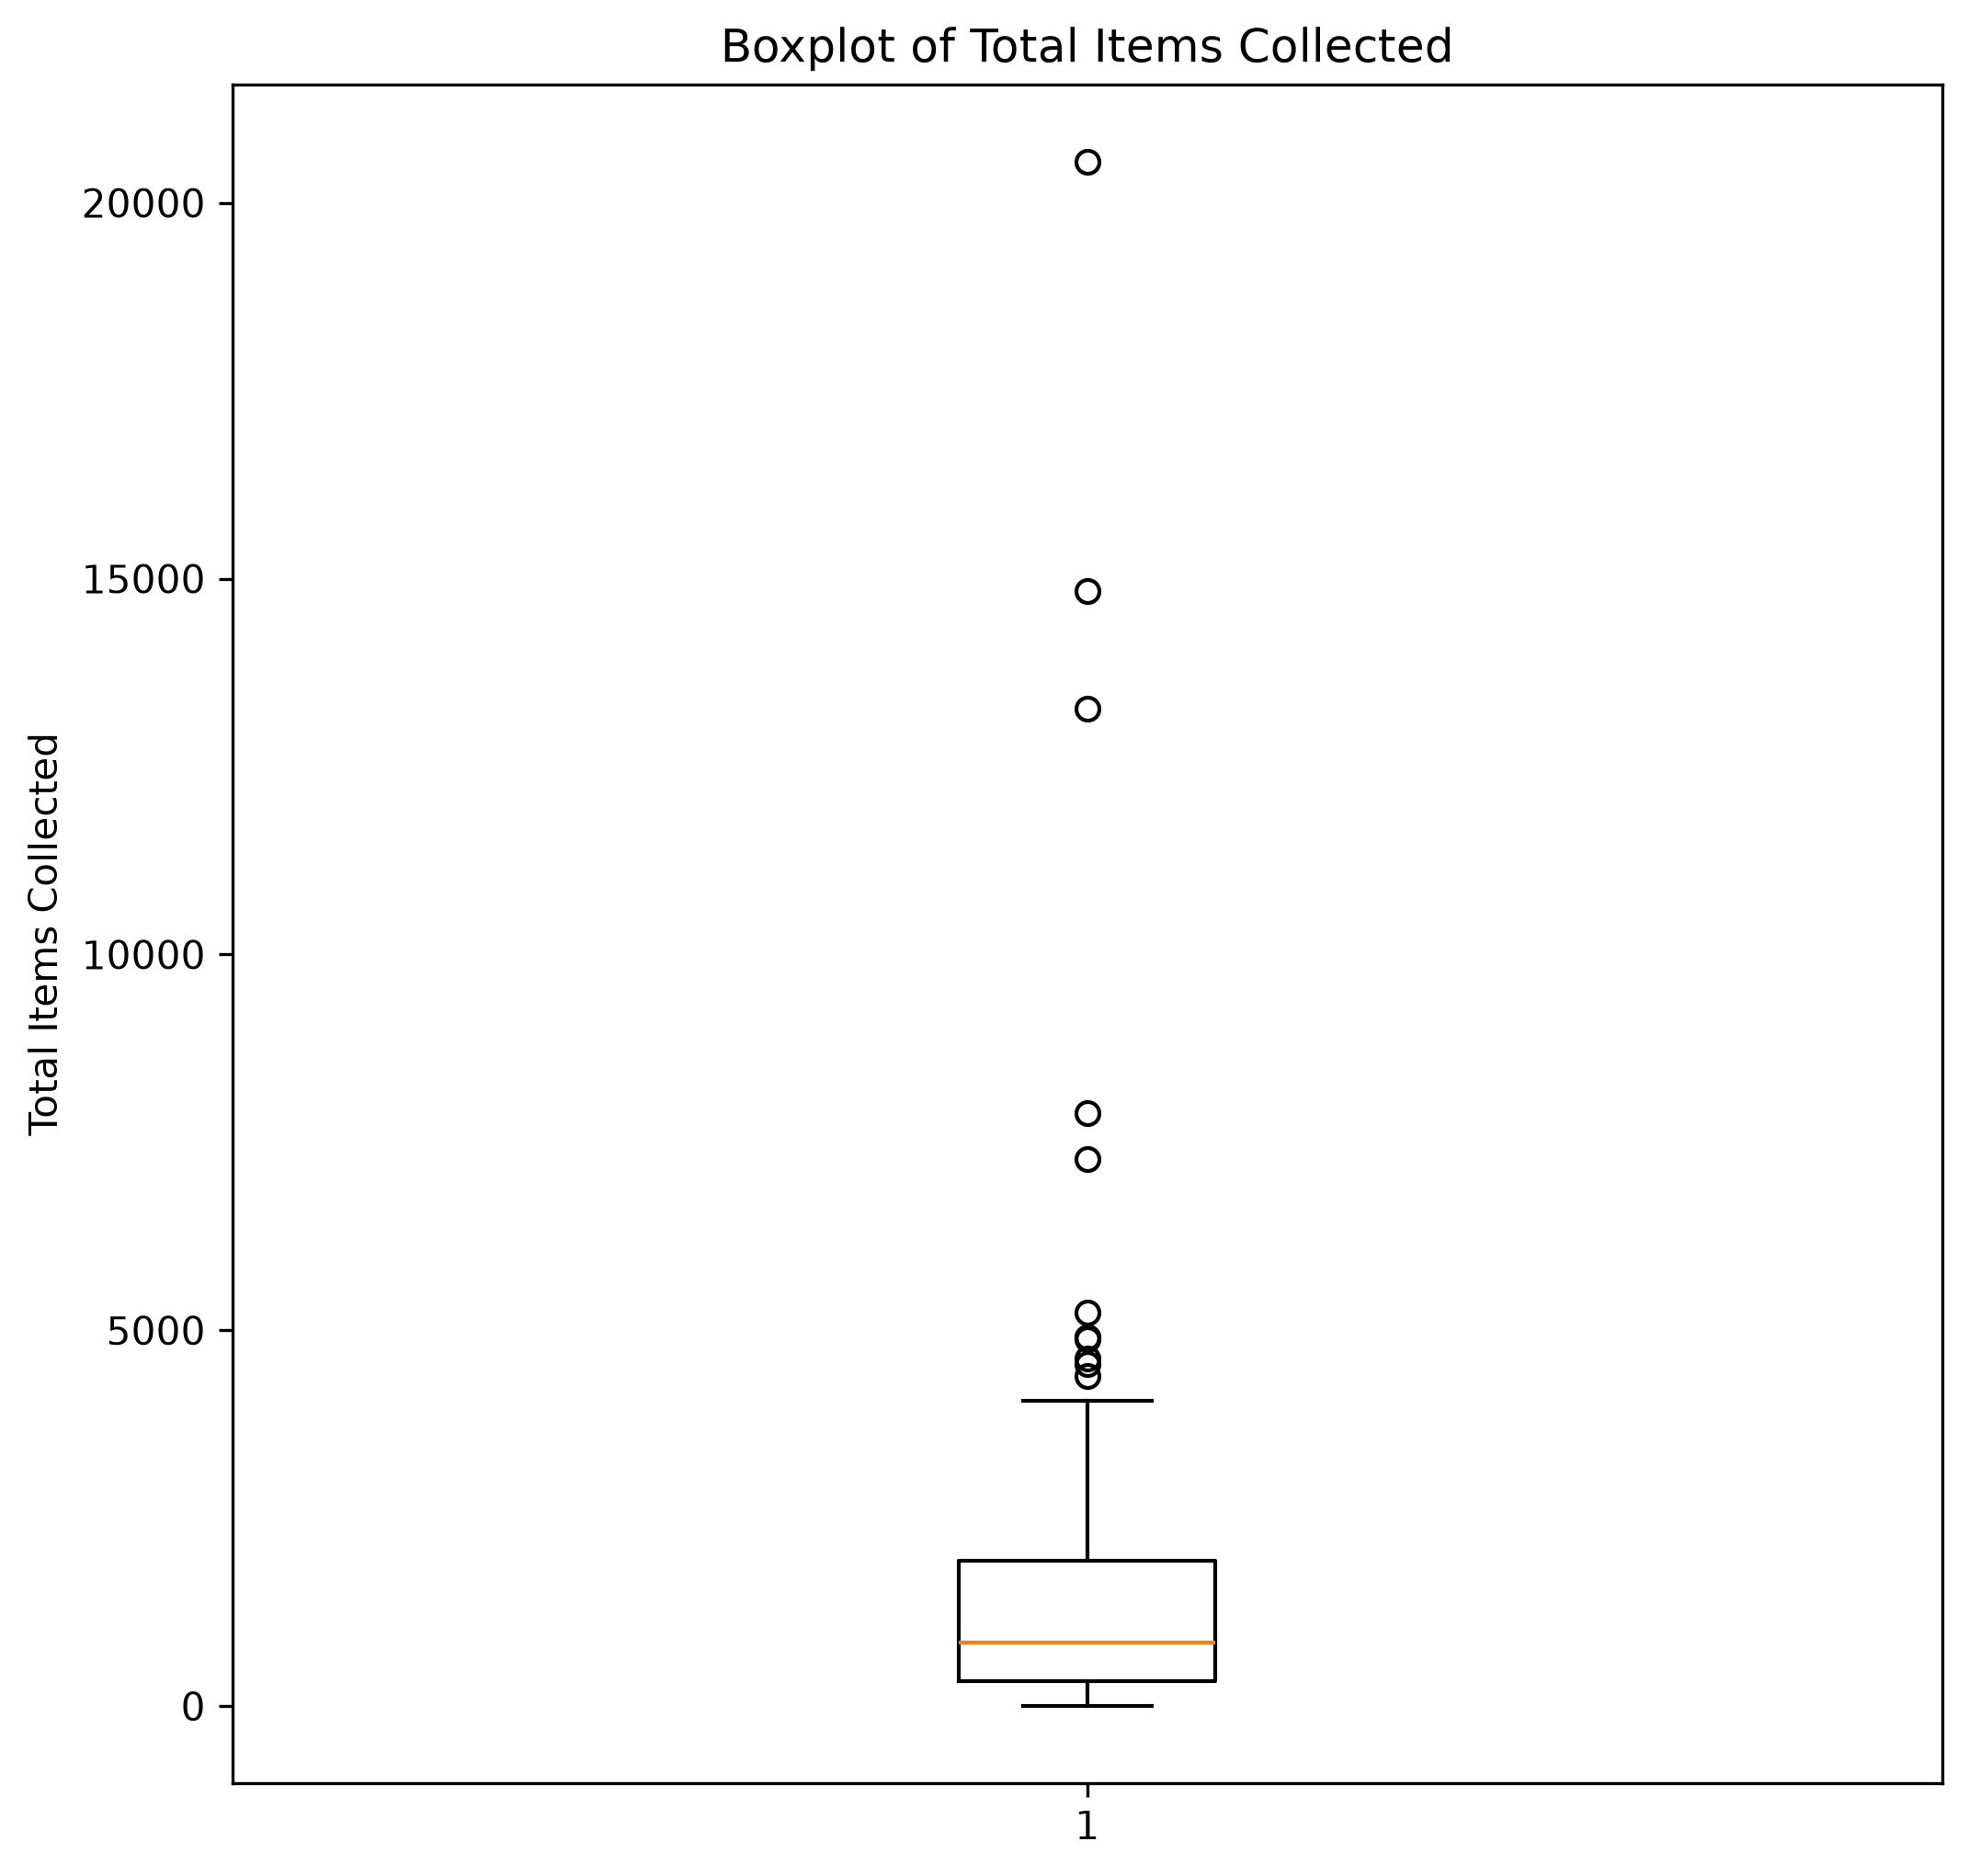

In [12]:
# Create a boxplot to look for outliers in Total Items Collected

fig, ax = plt.subplots(1, figsize=(8, 8), dpi=300)

plt.boxplot(data["Total Items Collected"].dropna())

plt.title("Boxplot of Total Items Collected")
plt.ylabel("Total Items Collected")

plt.show()

In [13]:
# 1. Select the pandas Series (NOT just the string name)
col = data["Total Items Collected"].dropna()

# 2. Convert to numeric if it was stored as text/string data
col = pd.to_numeric(col, errors='coerce').dropna()

# Calculate Quartiles and IQR
q1 = col.quantile(0.25)
q3 = col.quantile(0.75)
iqr = q3 - q1

# Define Whisker Limits (1.5 * IQR Rule)
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Identify Outliers
outliers = col[(col < lower_bound) | (col > upper_bound)]

print("=== Outlier Analysis ===")
print(f"Lower Bound Cutoff : {lower_bound}")
print(f"Upper Bound Cutoff : {upper_bound}")
print(f"Total Outlier Count: {len(outliers)}")
print("\nSpecific Outlier Values:")
print(outliers)

=== Outlier Analysis ===
Lower Bound Cutoff : -2061.5
Upper Bound Cutoff : 4334.5
Total Outlier Count: 12

Specific Outlier Values:
4      5238.0
9      4887.0
10     4551.0
20    13269.5
24     4626.0
39     7273.0
45    14830.0
50    20544.0
55     7892.0
57     4392.0
67     4904.0
70     4904.0
Name: Total Items Collected, dtype: float64


Using whisker limits (1.5 * IQR rule), 12 outliers were identified. The upper bound cutoff is 4334, and the highest outlier is 20544. All of the outliers are above the upper limit. This supports a right skewed distribution. 

In [14]:
data["Total Items Collected"].describe()

count       77.000000
mean      2059.474026
std       3408.767664
min          0.000000
25%        337.000000
50%        851.000000
75%       1936.000000
max      20544.000000
Name: Total Items Collected, dtype: float64

The mean is 2,059 which is significantly higher than the median value, 851. 

 Comparison question: If a cleanup has more volunteers, do they collect more items?

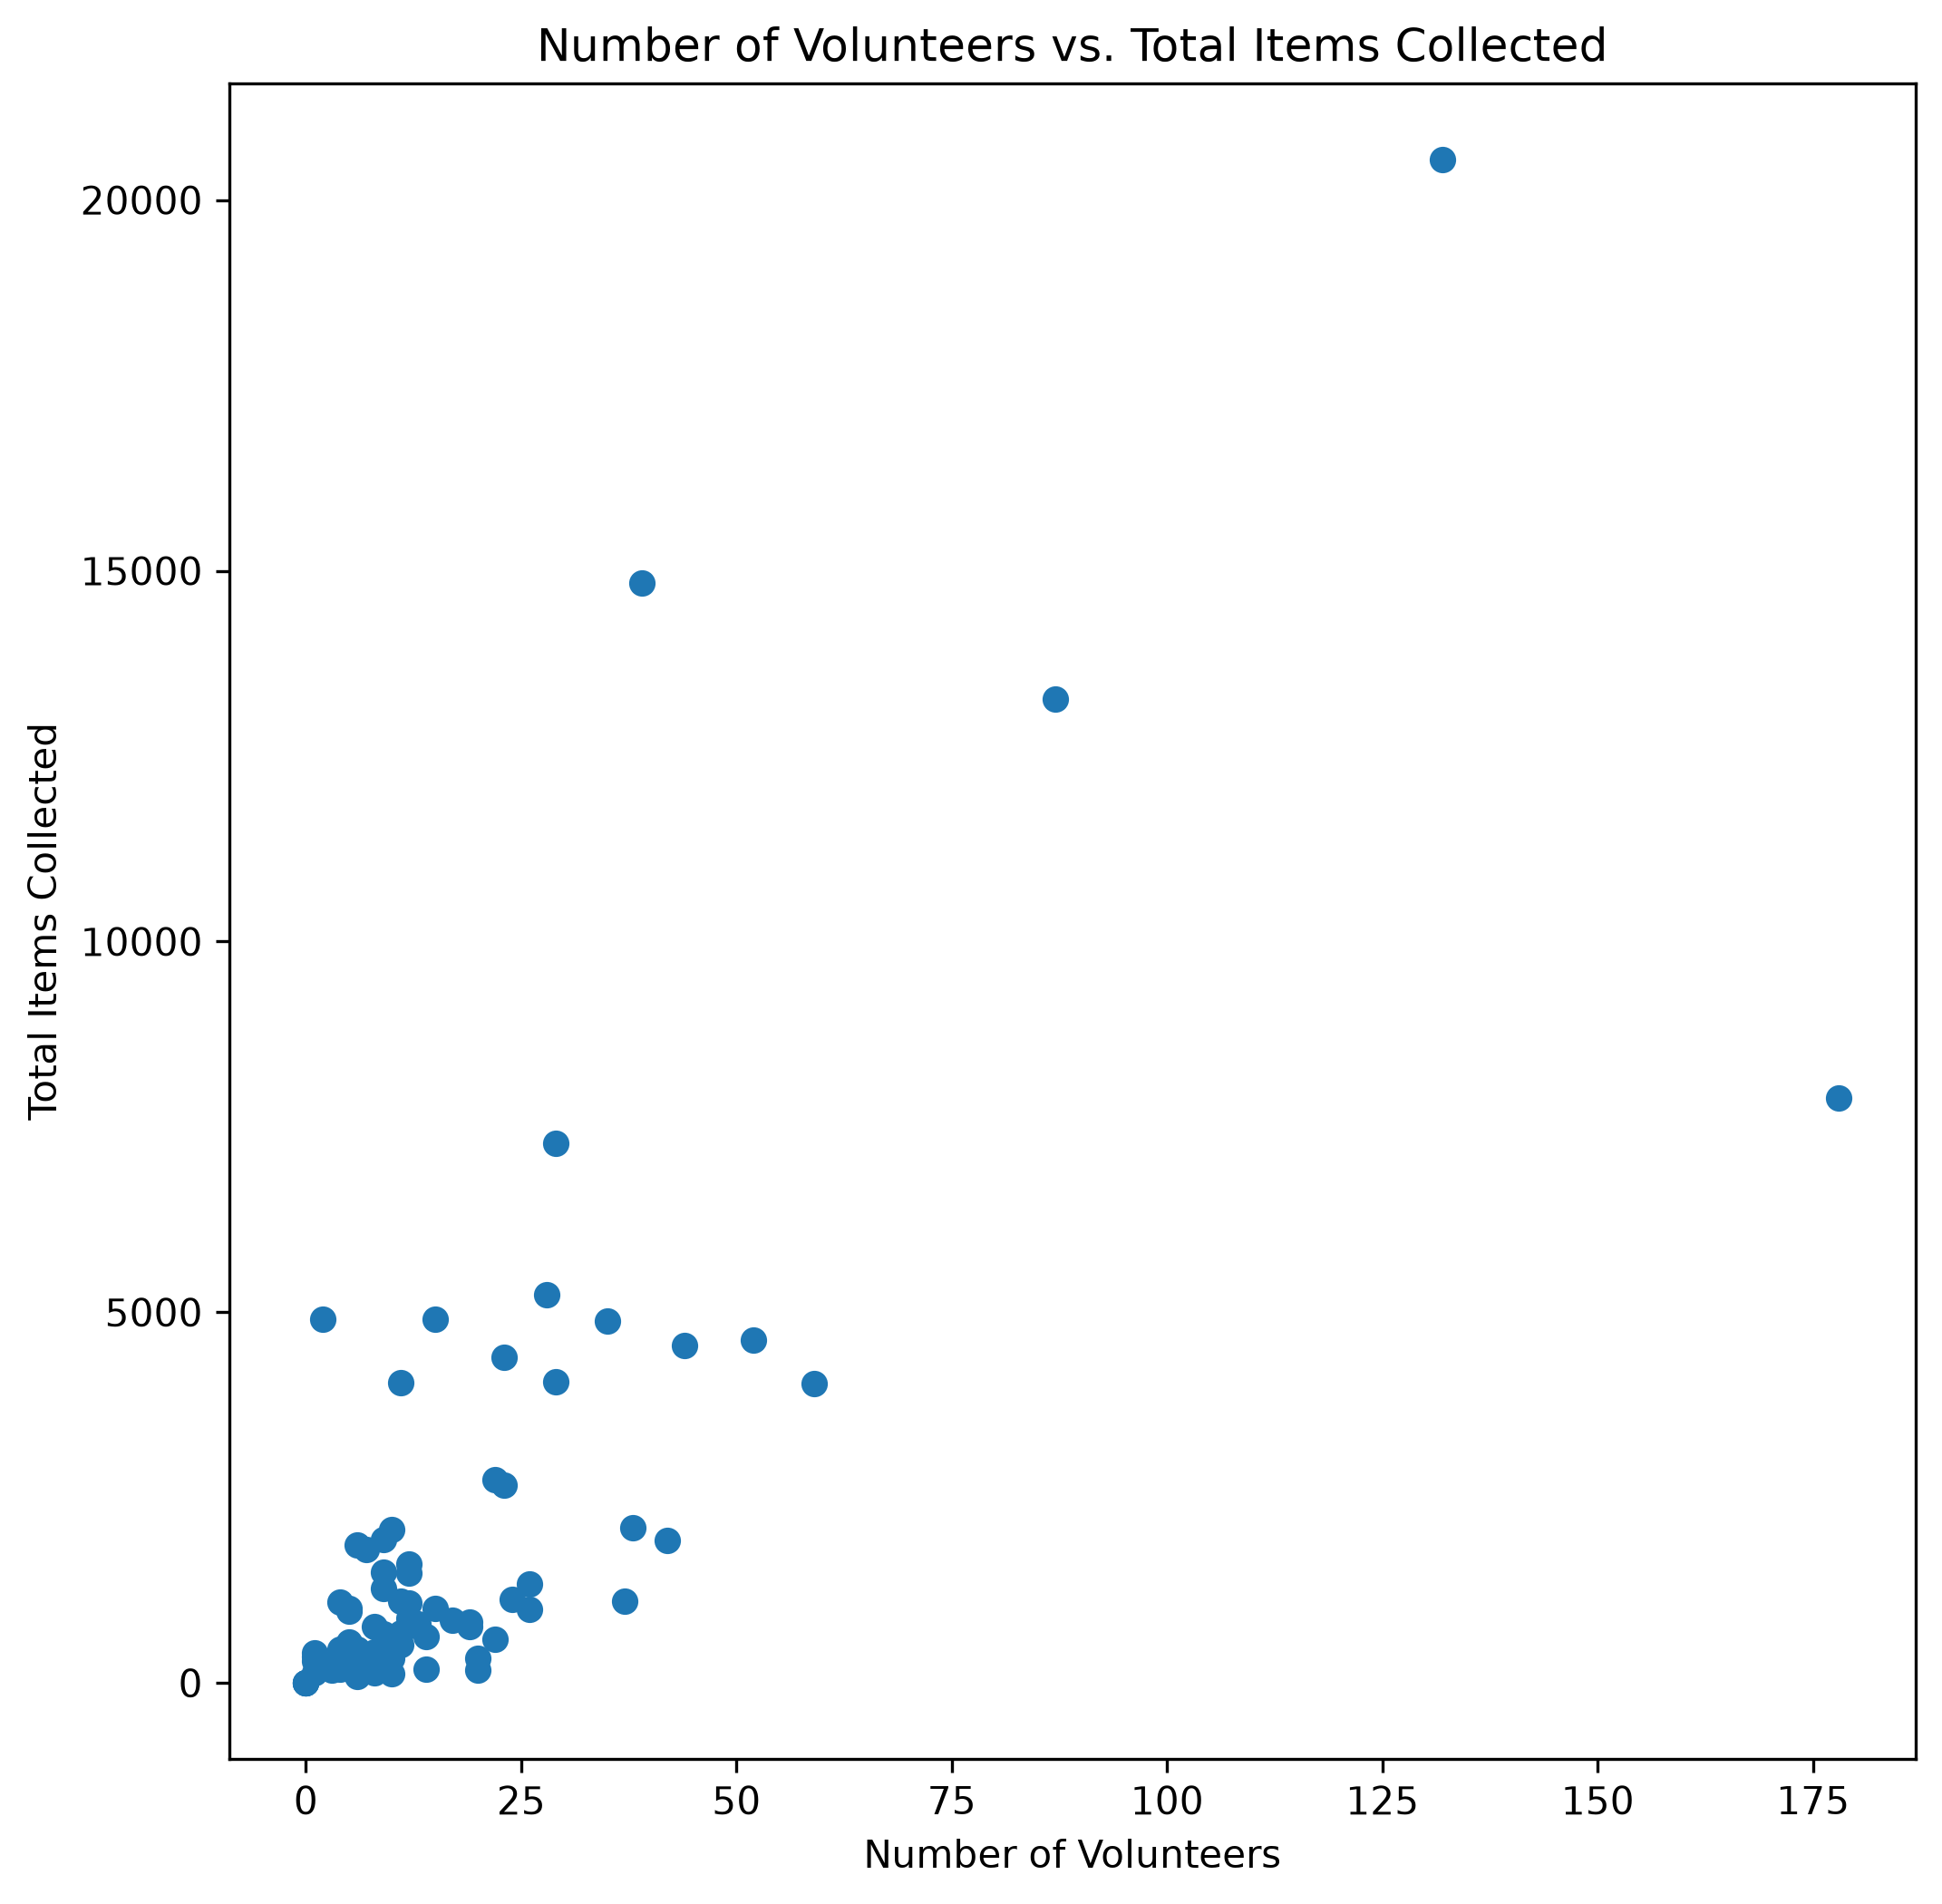

In [15]:
# Scatter plot of Number of Volunteers and Total Items Collected

fig, ax = plt.subplots(1, figsize=(8, 8), dpi=300)

plt.scatter(data["Number of Volunteers"], 
            data["Total Items Collected"])

plt.title("Number of Volunteers vs. Total Items Collected")
plt.xlabel("Number of Volunteers")
plt.ylabel("Total Items Collected")

plt.show()

In [16]:
# Calculate correlation between Number of Volunteers and Total Items Collected

data["Number of Volunteers"].corr(data["Total Items Collected"])

np.float64(0.7307601410089768)

A correlation of 0.7308 indicated a strong positive relationship between the number of volunteers and the total amount of items that were collected. 

In [17]:
# Calculate correlations between all numeric variables

correlation_matrix = data.corr(numeric_only=True)

correlation_matrix

,Cigarette Butts,"Food Wrappers (candy, chips, etc.)",Take Out/Away Containers (Plastic),Take Out/Away Containers (Foam),Bottle Caps (Plastic),Bottle Caps (Metal),Lids (Plastic),"Straws, Stirrers","Forks, Knives, Spoons",Beverage Bottles (Plastic),...,Tampons/Tampon Applicators,Personal Hygiene (Clean Swell),Foam Pieces,Glass Pieces,Plastic Pieces,Total Items Collected,Total Pounds of Litter Collected,Number of Volunteers,Volunteer Hours,Number of Miles
Cigarette Butts,1.000000,0.571074,0.255237,0.339120,0.698723,0.609342,0.355483,0.665355,0.544626,0.364068,...,0.144687,0.022706,0.391853,0.528334,0.228574,0.740820,0.436084,0.466998,0.543612,0.070772
"Food Wrappers (candy, chips, etc.)",0.571074,1.000000,0.467730,0.676394,0.716299,0.725218,0.618879,0.692558,0.620260,0.713001,...,0.407785,0.257176,0.623925,0.807933,0.486428,0.883929,0.628930,0.841800,0.821417,0.395803
Take Out/Away Containers (Plastic),0.255237,0.467730,1.000000,0.607496,0.356321,0.150825,0.700904,0.507858,0.370703,0.668326,...,0.375363,0.124749,0.447907,0.270914,0.229292,0.404370,0.262710,0.422706,0.388223,0.318016
Take Out/Away Containers (Foam),0.339120,0.676394,0.607496,1.000000,0.522715,0.497701,0.702081,0.426763,0.413820,0.826804,...,0.260685,0.078633,0.648022,0.616848,0.251848,0.635792,0.606671,0.611088,0.699840,0.169156
Bottle Caps (Plastic),0.698723,0.716299,0.356321,0.522715,1.000000,0.711129,0.471438,0.763219,0.714716,0.541608,...,0.201953,0.163837,0.465964,0.527321,0.375001,0.792166,0.475507,0.590190,0.629001,0.137659
Bottle Caps (Metal),0.609342,0.725218,0.150825,0.497701,0.711129,1.000000,0.347523,0.532873,0.559719,0.422048,...,-0.052693,0.062788,0.382773,0.789674,0.240316,0.818356,0.673098,0.581901,0.736923,0.066855
Lids (Plastic),0.355483,0.618879,0.700904,0.702081,0.471438,0.347523,1.000000,0.652222,0.592959,0.773948,...,0.416994,-0.024780,0.441191,0.425797,0.181321,0.531248,0.537670,0.656978,0.630329,0.347066
"Straws, Stirrers",0.665355,0.692558,0.507858,0.426763,0.763219,0.532873,0.652222,1.000000,0.817765,0.630540,...,0.286742,0.158761,0.407406,0.374861,0.354288,0.706259,0.434976,0.569830,0.528043,0.310443
"Forks, Knives, Spoons",0.544626,0.620260,0.370703,0.413820,0.714716,0.559719,0.592959,0.817765,1.000000,0.496002,...,0.267432,0.116772,0.308287,0.399666,0.334741,0.646199,0.443906,0.535732,0.541330,0.215445
Beverage Bottles (Plastic),0.364068,0.713001,0.668326,0.826804,0.541608,0.422048,0.773948,0.630540,0.496002,1.000000,...,0.308977,0.107821,0.614354,0.513336,0.266676,0.623641,0.531106,0.578888,0.614347,0.216427


In [18]:
# smaller correlation matrix

cleanup_vars = data[[
    "Total Items Collected",
    "Total Pounds of Litter Collected",
    "Number of Volunteers",
    "Volunteer Hours"
]]

cleanup_corr = cleanup_vars.corr()

cleanup_corr

,Total Items Collected,Total Pounds of Litter Collected,Number of Volunteers,Volunteer Hours
Total Items Collected,1.000000,0.667570,0.730760,0.808077
Total Pounds of Litter Collected,0.667570,1.000000,0.672149,0.837152
Number of Volunteers,0.730760,0.672149,1.000000,0.905277
Volunteer Hours,0.808077,0.837152,0.905277,1.000000


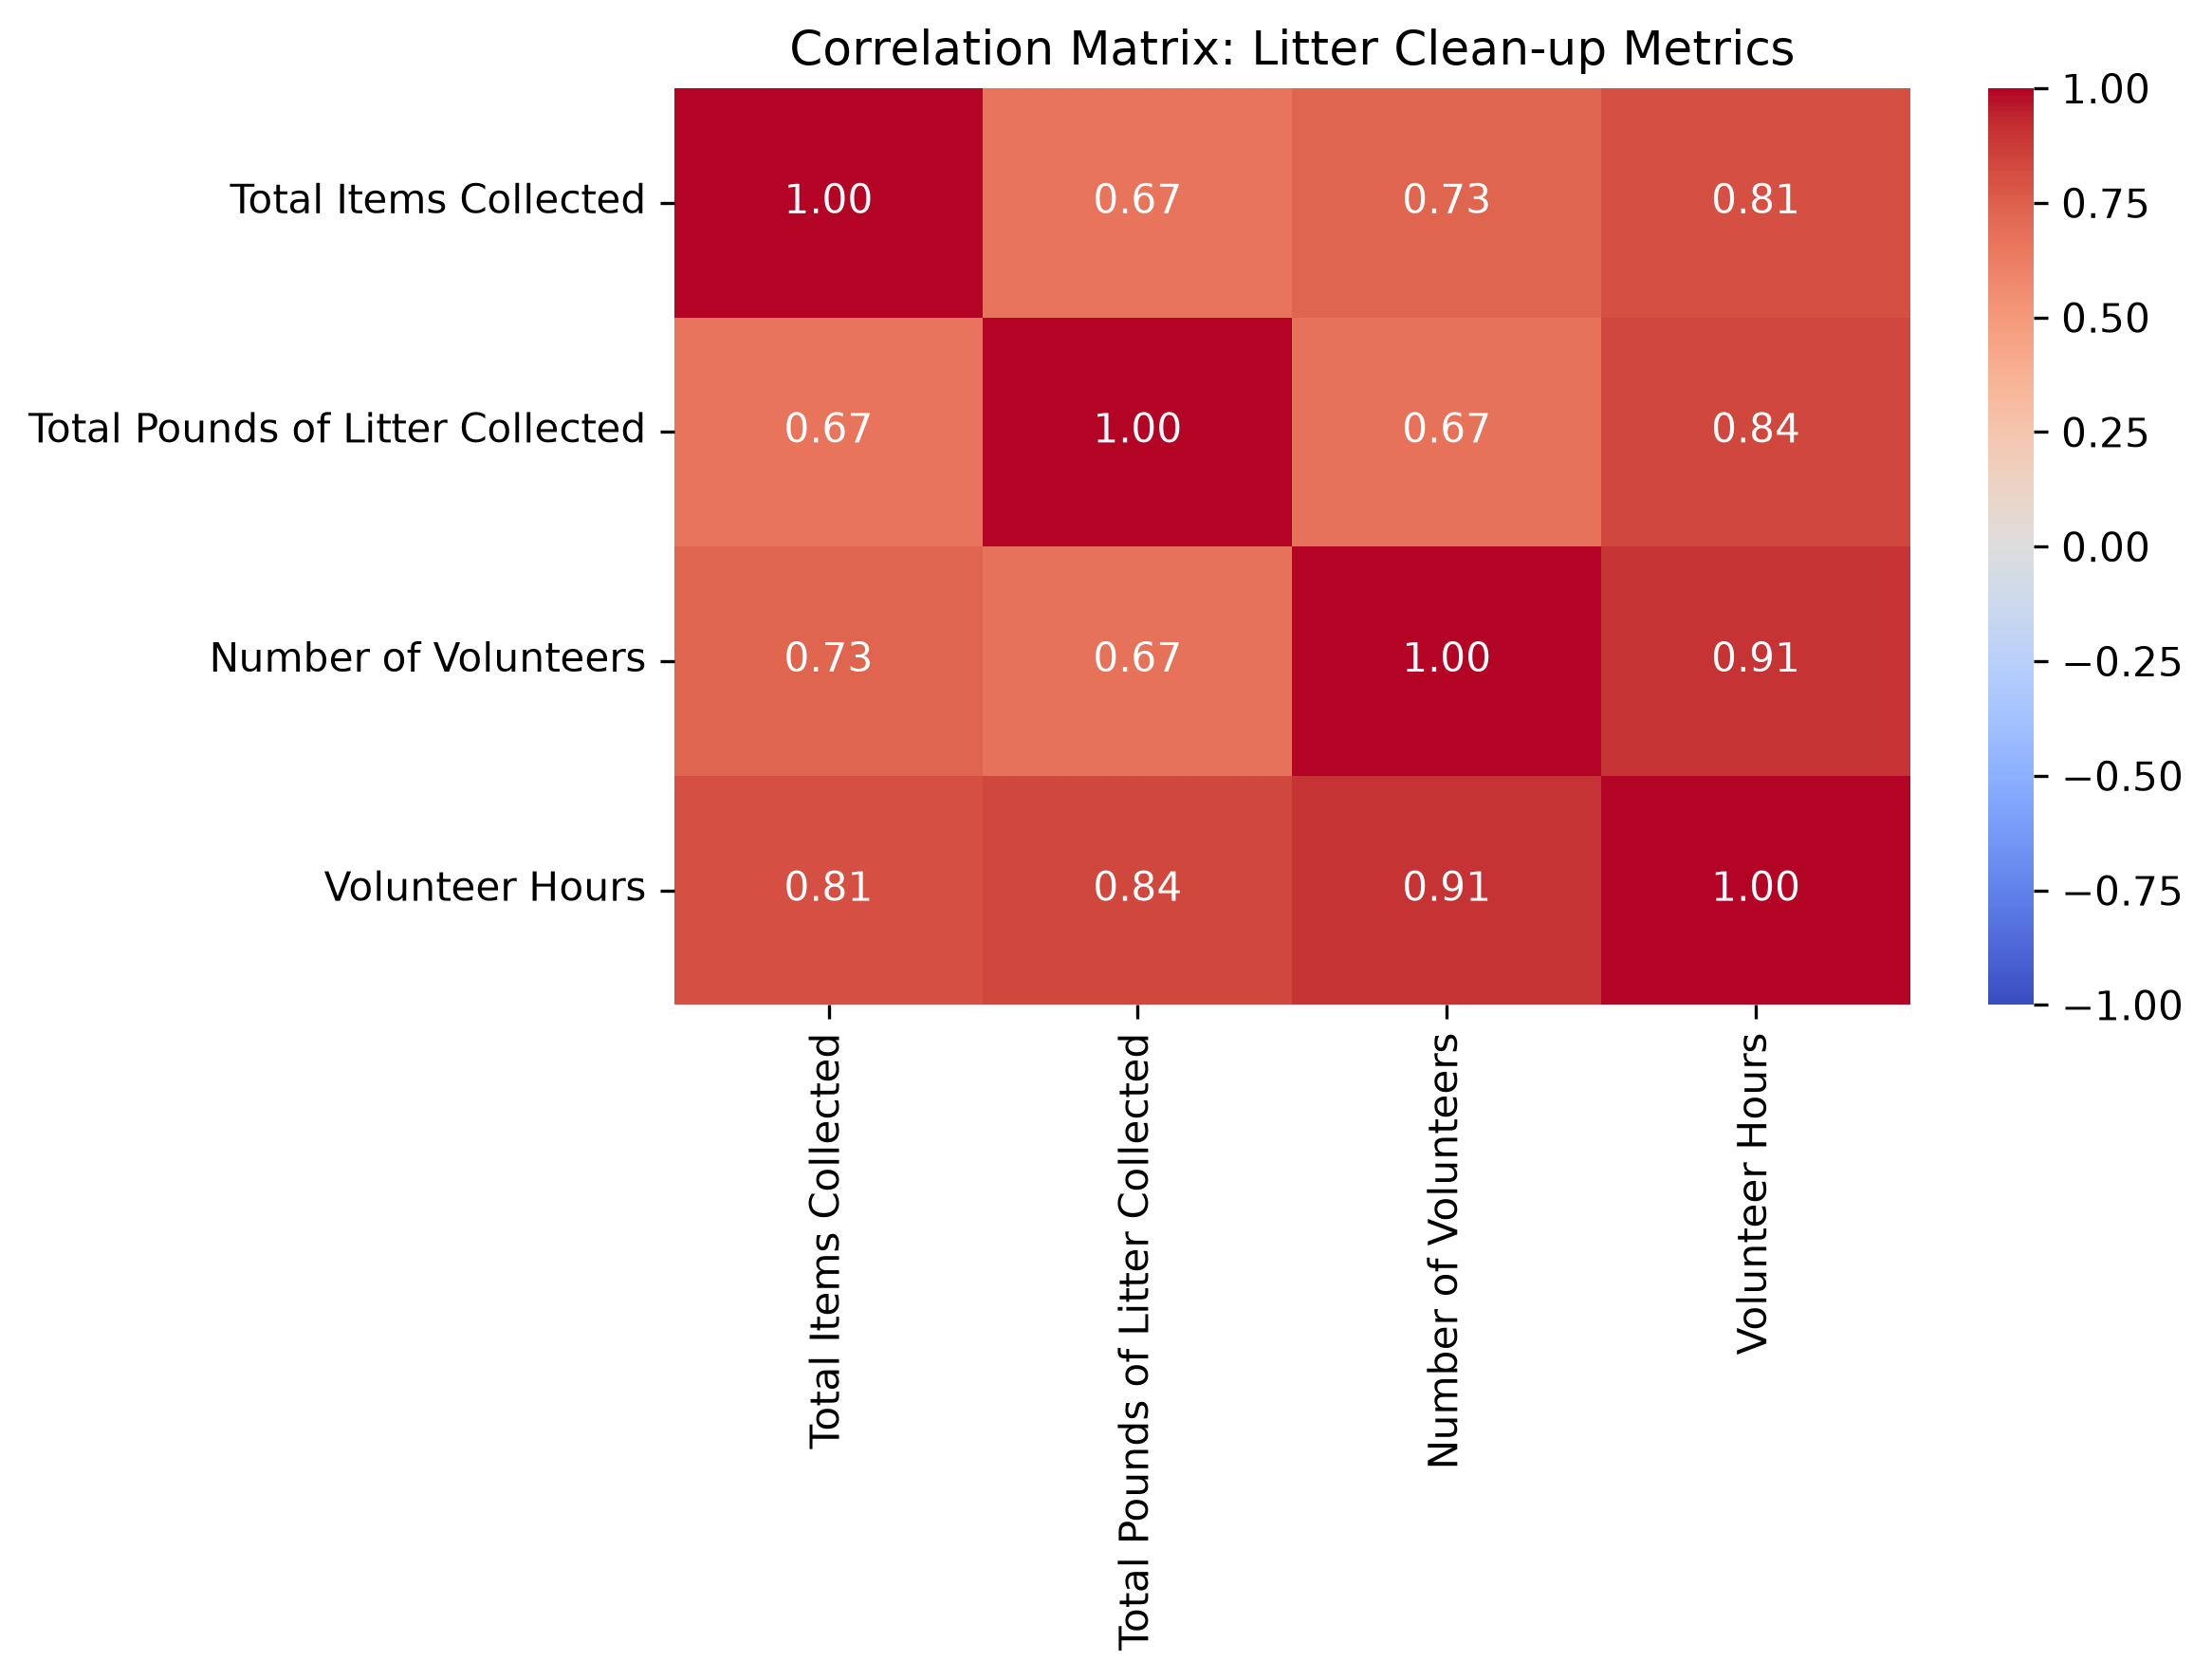

In [19]:
# Plotting the correlation matrix heatmap
plt.figure(figsize=(8, 6), dpi=300)
sns.heatmap(
    cleanup_corr, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, vmax=1, 
    cbar=True
)
plt.title("Correlation Matrix: Litter Clean-up Metrics")
plt.tight_layout()
plt.show()

The heat map shows the correlation matrix which have all positive correclations. The variables compared are total items collected, total pounds of litter collected, number of volunteers, and the number of volunteer hours. The strongest correlation was between the number of volunteers and the volunteer hours (r = 0.91). The second highest correlation is between the total pounds of litter collected with the volunteer hours (r = 0.84) and the volunteer hours with the total items collected was very similar (r = 0.81). Although still positive, some of the less positive correlations were between the number of volunteers and the total items collected (r = 0.73) and between the number of volunteers and the tital pounds of litter collected (r = 0.67). 

This is interesting to me because I expected the correltaion between the number of volunteers and the items collected to be higher than the number of volunteers wit volunteer hours. I expect there to be less hours completed if there were more volunteers. 